# Thread Count 02: tariff by product, exposure and seasonality

Effective tariff here means duty collected divided by the value of imports for consumption, for apparel (HS chapters 61 and 62).

Three periods, matching the tariff actions in `01_data/reference/tariff_events.csv`:

| Period | Months | What applied |
|---|---|---|
| Before | Jan to Dec 2024 | normal duty only |
| Peak | Oct 2025 to Jan 2026 | country reciprocal rates (Bangladesh 20%) on top of normal duty |
| Now | Mar to Sep 2026 | flat 10% (Section 122, then Section 301 from 24 July) on top of normal duty |

Questions:

1. How much did each country's tariff rise in each period, and how much of that is product mix?
2. Which Bangladesh products pay the most?
3. How much of each country's apparel is cotton, the fibre the US-cotton route in the February 2026 deal would affect?
4. How concentrated are Bangladesh's exports?
5. Is there a seasonal pattern, and did importers bring orders forward before the tariffs?

In [1]:
import duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "03_analysis" else Path.cwd()
con = duckdb.connect(str(ROOT / "01_data/processed/thread_count.duckdb"), read_only=True)

GREEN, OCHRE, TOMATO, SLATE, LIGHT = "#1D4A35", "#B87318", "#F2462E", "#7D8D99", "#3B8A60"
COLORS = {"bangladesh": TOMATO, "china": SLATE, "vietnam": GREEN, "india": OCHRE,
          "cambodia": LIGHT, "indonesia": "#A88B5C", "pakistan": "#9AA5A0", "sri_lanka": "#C9B89A"}
plt.rcParams.update({"figure.facecolor": "#F7F1E6", "axes.facecolor": "#F7F1E6", "axes.edgecolor": "#DCCFB6",
                     "axes.grid": True, "grid.color": "#E6DCC8", "axes.spines.top": False, "axes.axisbelow": True,
                     "axes.spines.right": False, "font.size": 10, "text.color": "#16382A",
                     "axes.labelcolor": "#4F5E52", "xtick.color": "#4F5E52", "ytick.color": "#4F5E52"})
pd.set_option("display.float_format", "{:,.2f}".format)

df = con.sql("""
select country, hs6, any_value(description) as descr, month, sum(con_value) as con_value,
       sum(gen_value) as gen_value, sum(duty) as duty
from silver.imports where chapter in ('61','62') group by country, hs6, month
""").df()
df["month"] = pd.to_datetime(df["month"])

def period(m):
    if m.year == 2024: return "before"
    if pd.Timestamp("2025-10-01") <= m <= pd.Timestamp("2026-01-01"): return "peak"
    if pd.Timestamp("2026-03-01") <= m <= pd.Timestamp("2026-09-01"): return "now"
    return None
df["period"] = df["month"].map(period)

def fibre(d):
    d = str(d).upper()
    if any(k in d for k in ["COTTON", "COTT", " COT", "COT,"]): return "cotton"
    if any(k in d for k in ["MAN-MADE", "MANMADE", "MMF", "MM F", "SYN", "ARTIF", "MAN MADE"]): return "man-made"
    if any(k in d for k in ["WOOL", "KASHMIR", "ANIMAL HAIR", "SILK"]): return "wool or silk"
    return "other or mixed"
desc = df.groupby("hs6")["descr"].first()
fib = desc.map(fibre)
df["fibre"] = df["hs6"].map(fib)
fib.value_counts()

descr
other or mixed    85
man-made          59
cotton            51
wool or silk      31
Name: count, dtype: int64

Fibre comes from the Census short description of each HS6 code, so it is approximate. "Other or mixed" covers codes described as "other textile materials" or with no fibre named.

## 1. Tariff rise by country, and how much is product mix

In [2]:
p = df.dropna(subset=["period"]).groupby(["country", "period"])[["con_value", "duty"]].sum()
rate = (100 * p["duty"] / p["con_value"]).unstack()[["before", "peak", "now"]]
rate["added_peak"] = rate["peak"] - rate["before"]
rate["added_now"] = rate["now"] - rate["before"]
rate.sort_values("now")

period,before,peak,now,added_peak,added_now
country,,,,,
india,14.17,63.07,23.41,48.90,9.24
pakistan,15.43,34.10,25.15,18.66,9.72
bangladesh,16.77,36.04,25.61,19.28,8.85
sri_lanka,16.87,37.40,25.79,20.54,8.92
cambodia,17.72,37.14,27.14,19.42,9.42
indonesia,18.38,37.53,27.87,19.16,9.50
vietnam,18.39,38.43,28.50,20.04,10.11
china,21.70,44.83,31.46,23.13,9.76


The "before" rate differs by country mostly because of product mix: US normal duty is higher on man-made fibre garments than on cotton ones. To separate mix from country treatment, the next cell prices each country's own product mix at the **average rate the seven countries other than China paid** for each product in that period. China is left out of the benchmark because its goods also carry Section 301 duties from 2018 and 2019. The world average is not used as the benchmark, because it includes duty-free partners such as Mexico and Central America.

In [3]:
pp = df.dropna(subset=["period"])
peer = pp[pp.country != "china"].groupby(["hs6", "period"])[["duty", "con_value"]].sum()
peer = (peer["duty"] / peer["con_value"]).rename("peer_rate").reset_index()
mix = pp.groupby(["country", "period", "hs6"])["con_value"].sum().rename("v").reset_index()
mix["wt"] = mix["v"] / mix.groupby(["country", "period"])["v"].transform("sum")
m2 = mix.merge(peer, on=["hs6", "period"]).assign(x=lambda d: d.wt * d.peer_rate)
mix_rate = (100 * m2.groupby(["country", "period"])["x"].sum()).unstack()[["before", "peak", "now"]]
cmp_ = pd.DataFrame({"actual_before": rate["before"], "mix_only_before": mix_rate["before"],
                     "actual_peak": rate["peak"], "mix_only_peak": mix_rate["peak"],
                     "actual_now": rate["now"], "mix_only_now": mix_rate["now"]})
for per in ["before", "peak", "now"]:
    cmp_[f"treatment_{per}"] = cmp_[f"actual_{per}"] - cmp_[f"mix_only_{per}"]
cmp_.sort_values("actual_now")

,actual_before,mix_only_before,actual_peak,mix_only_peak,actual_now,mix_only_now,treatment_before,treatment_peak,treatment_now
country,,,,,,,,,
india,14.17,14.25,63.07,40.26,23.41,23.63,-0.08,22.82,-0.23
pakistan,15.43,15.41,34.10,37.10,25.15,25.12,0.02,-3.00,0.04
bangladesh,16.77,16.75,36.04,38.88,25.61,26.10,0.02,-2.84,-0.49
sri_lanka,16.87,16.81,37.40,39.11,25.79,26.19,0.06,-1.71,-0.40
cambodia,17.72,17.65,37.14,39.57,27.14,27.40,0.07,-2.43,-0.26
indonesia,18.38,18.39,37.53,40.44,27.87,28.04,-0.01,-2.90,-0.17
vietnam,18.39,18.40,38.43,40.13,28.50,28.05,-0.01,-1.70,0.45
china,21.70,16.11,44.83,37.38,31.46,25.18,5.59,7.44,6.28


`mix_only` is what the country would pay if every product were charged the seven-country average rate for that product, so it reflects product mix alone. `treatment` is the rest: the country-specific part of the tariff. Before 2025 the seven paid the same normal duty, so their treatment is close to zero (any gap comes from finer product detail below HS6), while China sits above because of the 2018 to 2019 Section 301 duties.

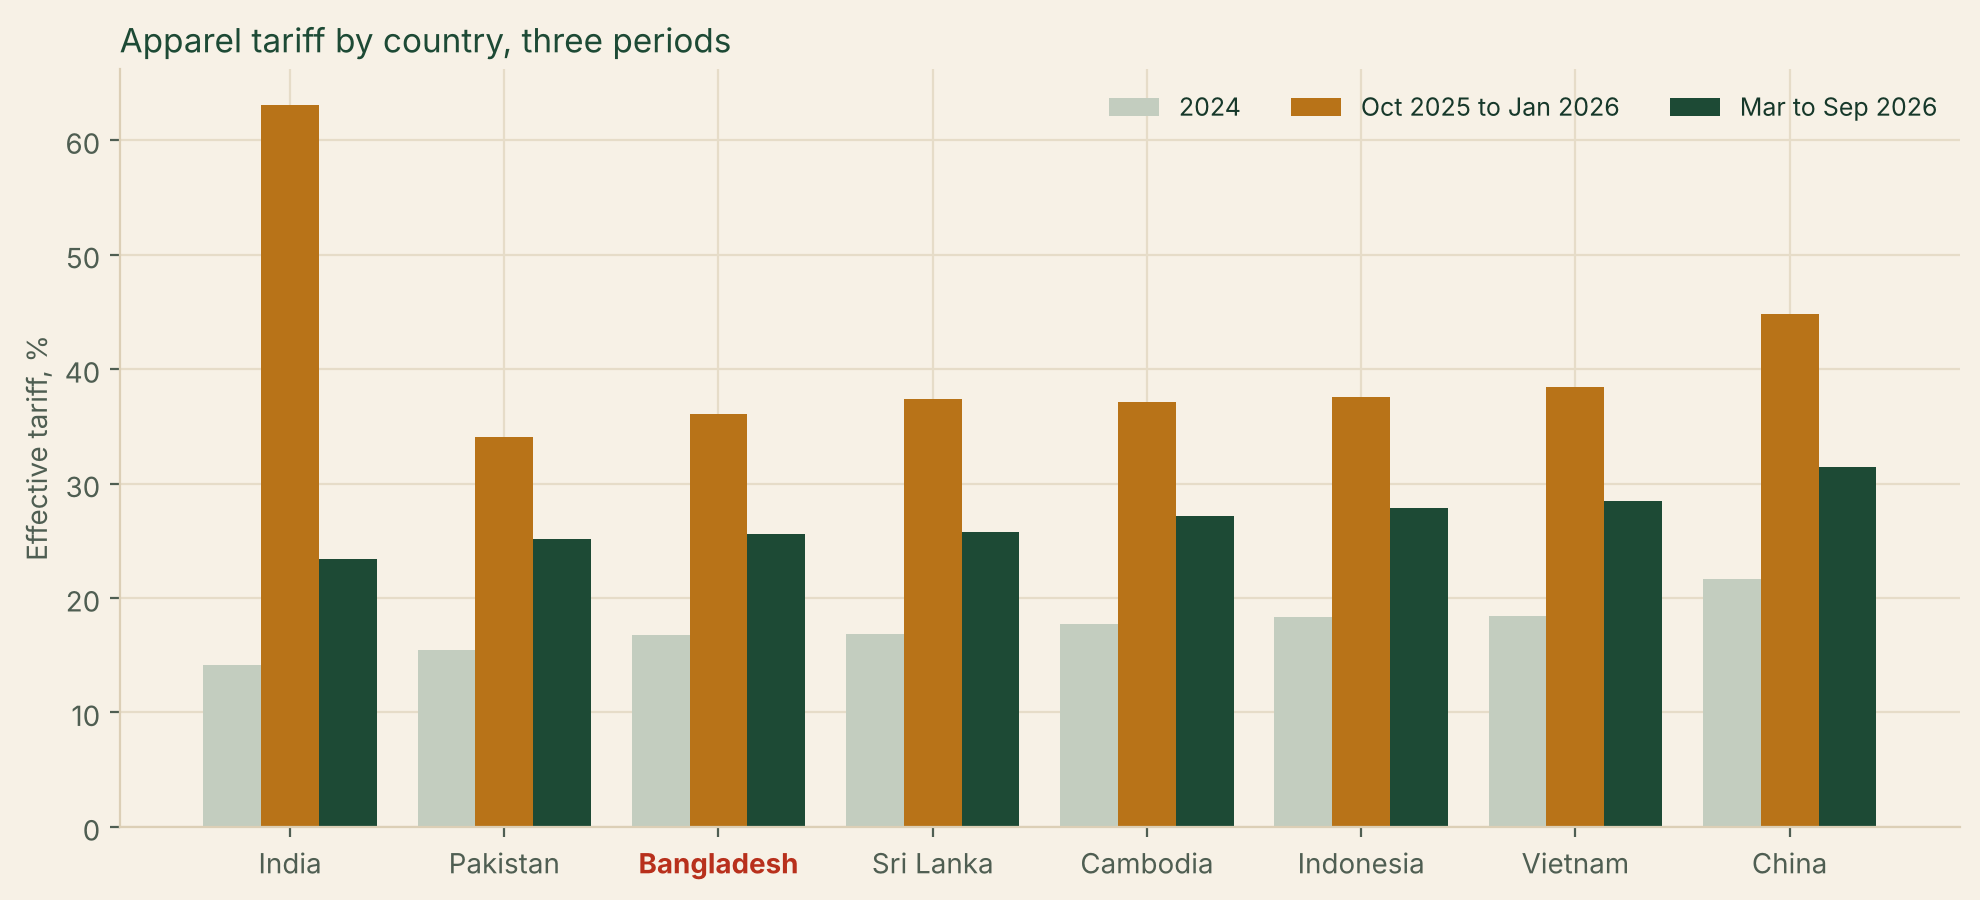

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.6))
order = rate.sort_values("now").index
x = np.arange(len(order)); bw = 0.27
for i, (col, colr, lab) in enumerate([("before", "#C3CDBF", "2024"), ("peak", OCHRE, "Oct 2025 to Jan 2026"), ("now", GREEN, "Mar to Sep 2026")]):
    ax.bar(x + (i - 1) * bw, rate.loc[order, col], bw, color=colr, label=lab)
ax.set_xticks(x, [c.replace("_", " ").title() for c in order])
for lbl in ax.get_xticklabels():
    if lbl.get_text() == "Bangladesh": lbl.set_color("#B8301C"); lbl.set_fontweight("bold")
ax.set_ylabel("Effective tariff, %")
ax.set_title("Apparel tariff by country, three periods", loc="left", fontsize=12, color=GREEN)
ax.legend(frameon=False, ncol=3, fontsize=9); plt.tight_layout(); plt.show()

## 2. Bangladesh: what each main product pays

In [5]:
bd = df[(df.country == "bangladesh") & df.period.notna()].groupby(["hs6", "period"])[["con_value", "duty"]].sum().unstack()
bdr = pd.DataFrame({
    "product": desc.loc[bd.index].str.slice(0, 48).values,
    "fibre": fib.loc[bd.index].values,
    "value_now_m": bd[("con_value", "now")] / 1e6,
    "rate_before": 100 * bd[("duty", "before")] / bd[("con_value", "before")],
    "rate_now": 100 * bd[("duty", "now")] / bd[("con_value", "now")],
}, index=bd.index)
bdr["share_of_bd_now"] = 100 * bdr["value_now_m"] / bdr["value_now_m"].sum()
bdr.sort_values("value_now_m", ascending=False).head(15)

,product,fibre,value_now_m,rate_before,rate_now,share_of_bd_now
hs6,,,,,,
620342,"MEN'S OR BOYS' TROUSERS ETC, NOT KNIT, COTTON",cotton,881.84,16.52,25.24,18.78
620462,"WOMEN'S OR GIRLS' TROUSERS ETC NOT KNIT, COTTON",cotton,591.14,16.39,25.67,12.59
611020,"SWEATERS, PULLOVERS ETC, KNIT ETC, COTTON",cotton,393.09,16.46,25.77,8.37
610910,"T-SHIRTS, SINGLETS, TANK TOPS ETC, KNIT ETC COTT",cotton,311.08,16.50,23.96,6.62
620520,"MEN'S OR BOYS' SHIRTS, NOT KNIT, OF COTTON",cotton,274.26,19.70,28.84,5.84
620343,"MEN'S OR BOYS' TROUSERS ETC, NOT KNIT, SYNTH FIB",man-made,182.10,22.66,31.02,3.88
611030,"SWEATERS, PULLOVERS ETC, KNIT ETC, MANMADE FIBER",man-made,120.02,31.81,41.18,2.56
620140,MEN'S OR BOYS' OVERCOAT ETC OF MAN-MADE FIBERS,man-made,114.22,11.78,21.24,2.43
611120,"BABIES' GARMENTS & CLTHNG ACCESS OF COTTON, KNIT",cotton,100.59,10.16,19.43,2.14


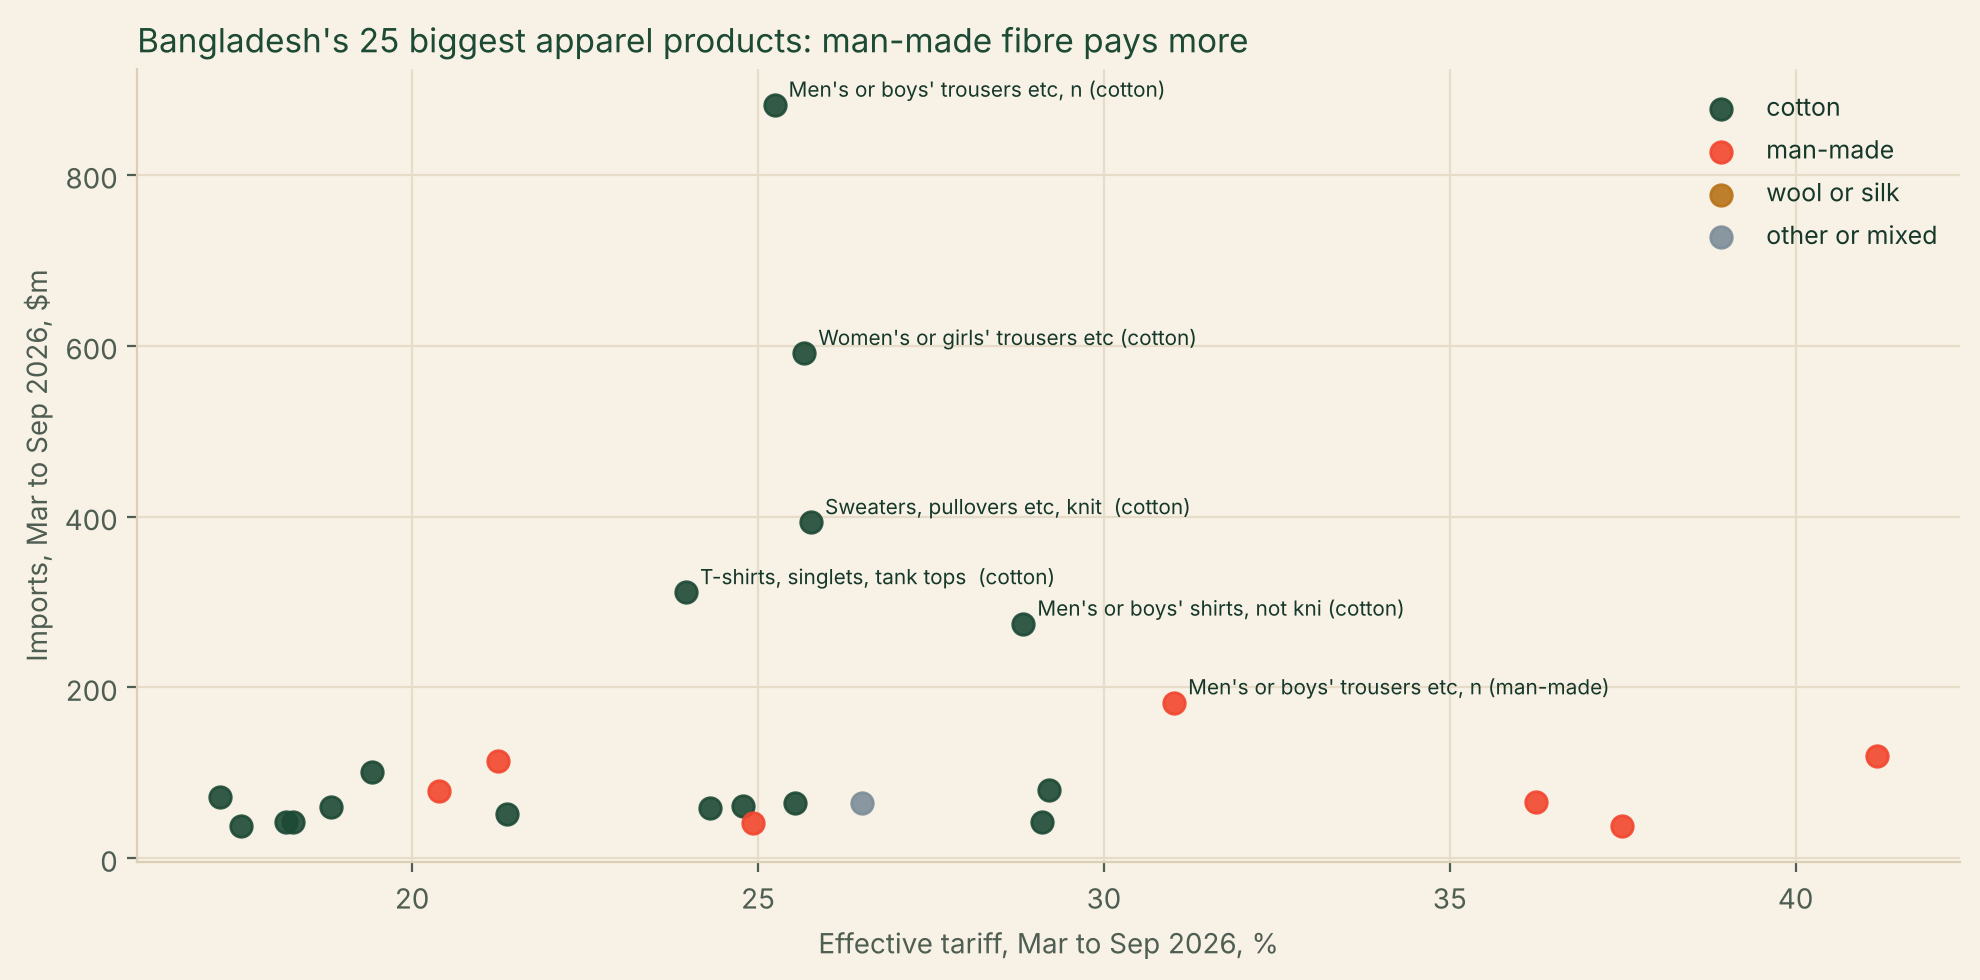

In [6]:
top = bdr.sort_values("value_now_m", ascending=False).head(25)
fig, ax = plt.subplots(figsize=(10, 5))
for f, colr in [("cotton", GREEN), ("man-made", TOMATO), ("wool or silk", OCHRE), ("other or mixed", SLATE)]:
    d = top[top.fibre == f]
    ax.scatter(d.rate_now, d.value_now_m, s=60, color=colr, label=f, alpha=.9)
for h, r in top.head(6).iterrows():
    ax.annotate(r["product"][:30].capitalize() + f" ({r.fibre})", (r.rate_now, r.value_now_m), fontsize=7.5, xytext=(5, 3), textcoords="offset points")
ax.set_xlabel("Effective tariff, Mar to Sep 2026, %"); ax.set_ylabel("Imports, Mar to Sep 2026, $m")
ax.set_title("Bangladesh's 25 biggest apparel products: man-made fibre pays more", loc="left", fontsize=12, color=GREEN)
ax.legend(frameon=False, fontsize=9); plt.tight_layout(); plt.show()

## 3. Fibre mix: how much is cotton

In [7]:
f = df[df.month.dt.year.isin([2024, 2026]) & (df.month.dt.month <= 9)]
fm = f.groupby(["country", f.month.dt.year.rename("year"), "fibre"])["gen_value"].sum()
fm = (100 * fm / fm.groupby(level=[0, 1]).transform("sum")).unstack("fibre")
fm.xs(2026, level="year").sort_values("cotton", ascending=False)

fibre,cotton,man-made,other or mixed,wool or silk
country,,,,
pakistan,87.07,8.34,4.53,0.06
india,75.87,13.84,8.94,1.35
bangladesh,70.67,20.82,8.36,0.15
cambodia,45.91,38.24,10.96,4.89
indonesia,41.78,40.73,15.81,1.67
vietnam,37.88,46.54,14.31,1.27
sri_lanka,36.51,32.93,30.22,0.34
china,24.57,44.88,25.13,5.42


In [8]:
fr = df[df.period == "now"].groupby(["country", "fibre"])[["duty", "con_value"]].sum()
(100 * fr["duty"] / fr["con_value"]).unstack().round(1)

fibre,cotton,man-made,other or mixed,wool or silk
country,,,,
bangladesh,24.60,30.90,21.30,24.10
cambodia,24.60,33.10,21.40,19.00
china,31.70,35.90,24.60,26.50
india,22.90,28.90,18.60,23.50
indonesia,24.80,33.00,23.10,26.50
pakistan,25.10,28.30,21.10,22.90
sri_lanka,22.30,31.10,24.30,22.00
vietnam,25.40,32.70,23.30,25.70


Cotton garments pay less normal duty than man-made fibre ones, so a cotton-heavy country starts lower. The February 2026 agreement promised a zero reciprocal rate for garments made with US cotton or man-made fibre; with the IEEPA tariffs struck down two weeks later, how that applies to the current 10% is not yet clear.

## 4. Exposure and concentration

In [9]:
now = df[df.period == "now"].groupby(["country", "hs6"])[["con_value", "duty"]].sum()
now["rate"] = now["duty"] / now["con_value"]
exp = now.groupby("country").apply(lambda d: pd.Series({
    "value_now_bn": d.con_value.sum() / 1e9,
    "pct_value_rate_ge_30": 100 * d.loc[d.rate >= .30, "con_value"].sum() / d.con_value.sum(),
    "top5_share_pct": 100 * d.con_value.nlargest(5).sum() / d.con_value.sum(),
    "top10_share_pct": 100 * d.con_value.nlargest(10).sum() / d.con_value.sum(),
    "hhi": ((d.con_value / d.con_value.sum()) ** 2).sum() * 10000,
}))
exp.sort_values("top10_share_pct", ascending=False)

,value_now_bn,pct_value_rate_ge_30,top5_share_pct,top10_share_pct,hhi
country,,,,,
pakistan,1.42,2.60,67.09,79.80,"1,100.30"
bangladesh,4.70,13.68,52.20,64.92,722.40
sri_lanka,1.02,18.97,39.06,56.86,496.78
india,2.39,4.87,36.94,54.26,401.42
cambodia,3.10,25.76,35.47,49.41,419.37
indonesia,2.84,27.41,30.32,43.41,314.41
vietnam,9.92,30.10,25.95,42.86,275.02
china,5.90,61.37,23.83,35.99,208.16


HHI is the Herfindahl index of the country's own product mix (0 to 10,000; higher means fewer products carry the exports).

## 5. Seasonality and front-loading

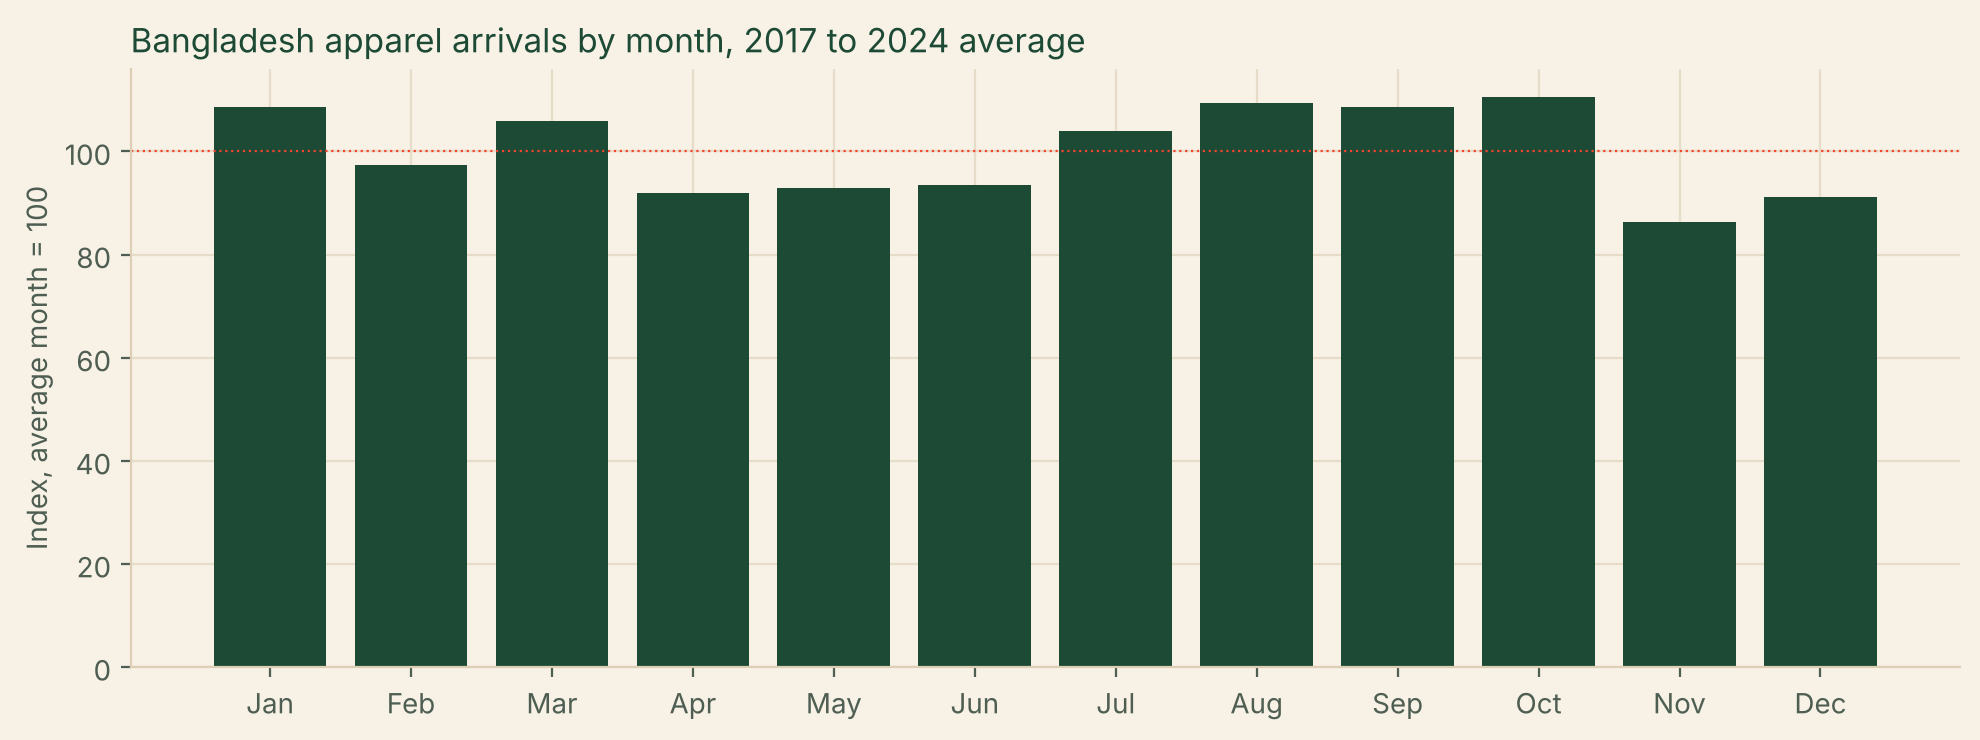

month,1,2,3,4,5,6,7,8,9,10,11,12
index,109.00,97.00,106.00,92.00,93.00,93.00,104.00,109.00,109.00,110.00,86.00,91.00


In [10]:
bdm = df[df.country == "bangladesh"].groupby("month")["gen_value"].sum()
base = bdm["2017":"2024"]
idx = base.groupby(base.index.month).mean() / base.mean() * 100
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(range(1, 13), idx.values, color=GREEN)
ax.axhline(100, color=TOMATO, lw=.8, ls=":")
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("Index, average month = 100")
ax.set_title("Bangladesh apparel arrivals by month, 2017 to 2024 average", loc="left", fontsize=12, color=GREEN)
plt.tight_layout(); plt.show()
idx.round(0).to_frame("index").T

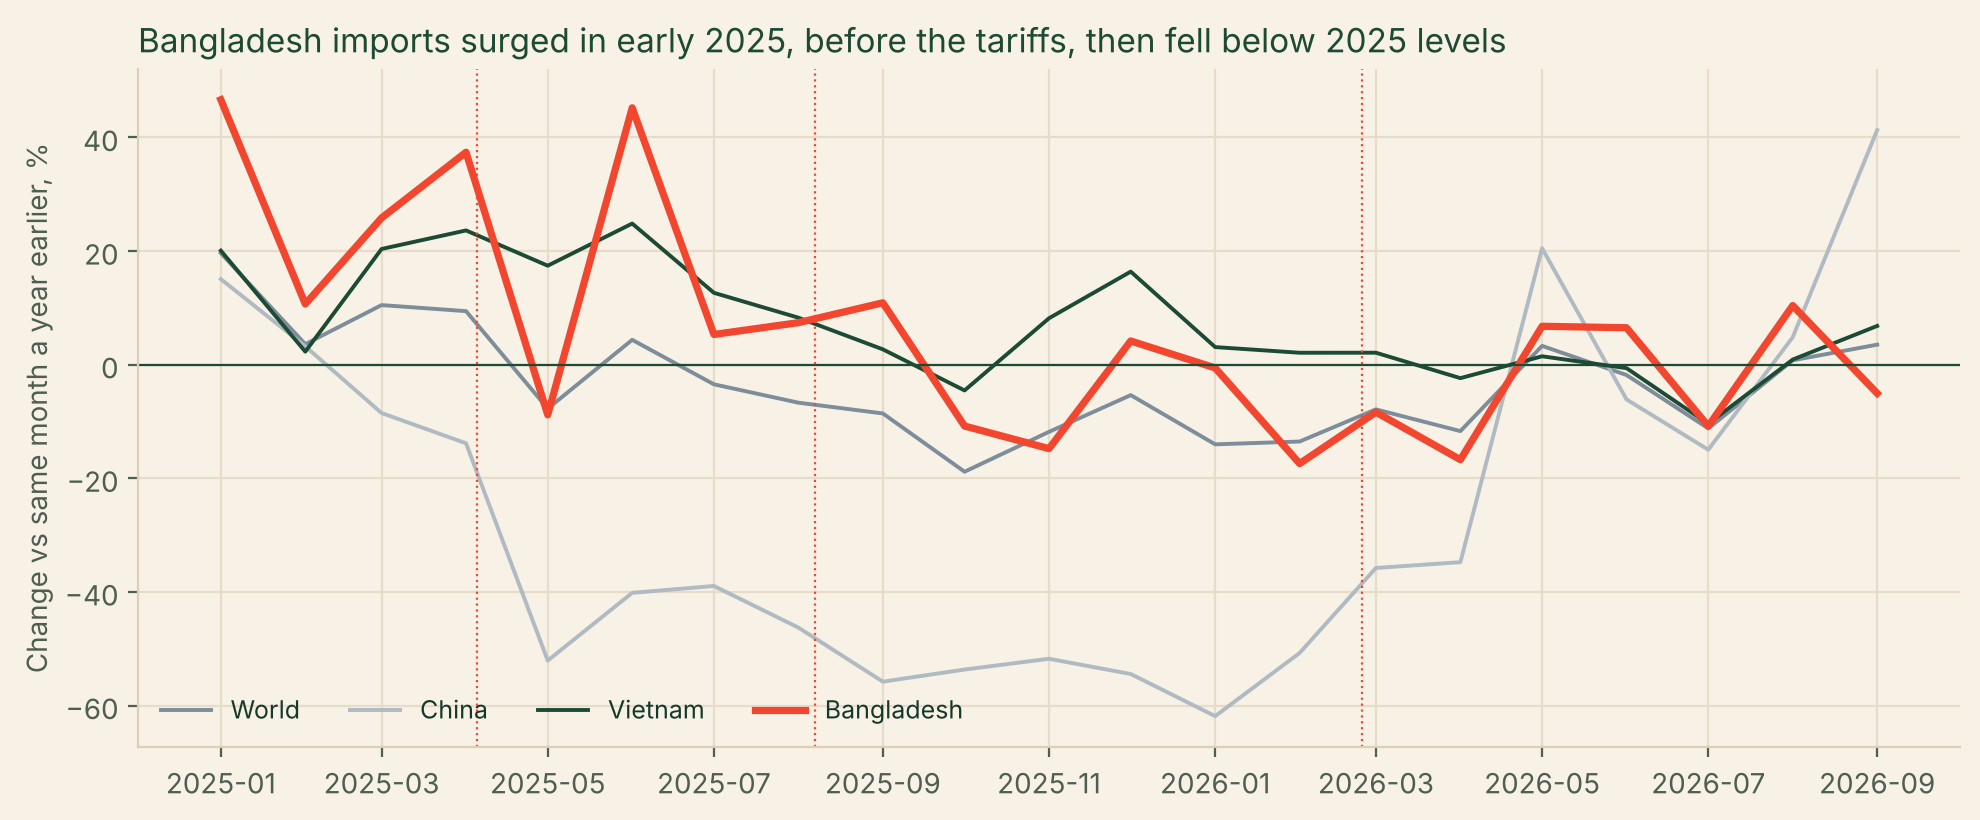

month,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,...,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01,2026-09-01
country,,,,,,,,,,,,,,,,,,,,,
bangladesh,46.60,10.70,25.80,37.40,-8.80,45.20,5.30,7.40,10.90,-10.80,...,4.20,-0.60,-17.40,-8.40,-16.70,6.80,6.50,-10.80,10.40,-5.00
vietnam,20.10,2.30,20.40,23.60,17.40,24.90,12.70,8.30,2.70,-4.50,...,16.40,3.10,2.10,2.10,-2.40,1.50,-0.60,-10.40,0.90,6.80
china,15.10,3.20,-8.50,-13.80,-52.10,-40.20,-39.00,-46.30,-55.80,-53.70,...,-54.50,-61.90,-50.70,-35.80,-34.80,20.50,-6.10,-15.00,4.80,41.30
world,19.60,3.60,10.50,9.40,-7.70,4.40,-3.50,-6.70,-8.60,-18.80,...,-5.40,-14.00,-13.50,-7.90,-11.70,3.30,-1.80,-11.20,0.80,3.50


In [11]:
# Year on year change by month, 2025 and 2026, Bangladesh vs China vs world
def yoy(series):
    s = series.copy(); return 100 * (s / s.shift(12) - 1)
g = df.groupby(["country", "month"])["gen_value"].sum().unstack(0)
wm = con.sql("select month, sum(gen_value) v from silver.world where chapter in ('61','62') group by 1 order by 1").df()
wm["month"] = pd.to_datetime(wm["month"]); g["world"] = wm.set_index("month")["v"]
y = g.apply(yoy)["2025-01-01":]
fig, ax = plt.subplots(figsize=(10, 4.2))
for c, colr, lw in [("world", SLATE, 1.4), ("china", "#B0BAC2", 1.4), ("vietnam", GREEN, 1.4), ("bangladesh", TOMATO, 2.6)]:
    ax.plot(y.index, y[c], color=colr, lw=lw, label=c.title())
ax.axhline(0, color=GREEN, lw=.8)
for d in ["2025-04-05", "2025-08-07", "2026-02-24"]:
    ax.axvline(pd.Timestamp(d), color=TOMATO, lw=.8, ls=":")
ax.set_ylabel("Change vs same month a year earlier, %")
ax.set_title("Bangladesh imports surged in early 2025, before the tariffs, then fell below 2025 levels", loc="left", fontsize=12, color=GREEN)
ax.legend(frameon=False, ncol=4, fontsize=9); plt.tight_layout(); plt.show()
y[["bangladesh", "vietnam", "china", "world"]].round(1).T

## Notes for the next steps

* All rates are duty collected on goods entered, so refunds of IEEPA duty (still in court) are not reflected.
* Fibre is approximate, from short descriptions.
* Next: a forecast of Bangladesh's share and value under the current 10% rate, then the review script and the Power BI report.